# EDA, 2 part

Подключаем библиотеки (взяла из нашего гп2)

In [19]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from datetime import datetime

import statsmodels.formula.api as smf
from scipy import stats

import plotly.express as px
import plotly.graph_objects as go


#import plotly.figure_factory as ff
#from scipy.stats import gaussian_kde

# Настройка стиля
plt.style.use('seaborn-v0_8-darkgrid')
sns.set_palette("husl")

In [20]:
df = pd.read_csv('bank-full.csv', sep=';')

In [21]:
df

,age,job,marital,education,default,balance,housing,loan,contact,day,month,duration,campaign,pdays,previous,poutcome,y
0,58,management,married,tertiary,no,2143,yes,no,unknown,5,may,261,1,-1,0,unknown,no
1,44,technician,single,secondary,no,29,yes,no,unknown,5,may,151,1,-1,0,unknown,no
2,33,entrepreneur,married,secondary,no,2,yes,yes,unknown,5,may,76,1,-1,0,unknown,no
3,47,blue-collar,married,unknown,no,1506,yes,no,unknown,5,may,92,1,-1,0,unknown,no
4,33,unknown,single,unknown,no,1,no,no,unknown,5,may,198,1,-1,0,unknown,no
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
45206,51,technician,married,tertiary,no,825,no,no,cellular,17,nov,977,3,-1,0,unknown,yes
45207,71,retired,divorced,primary,no,1729,no,no,cellular,17,nov,456,2,-1,0,unknown,yes
45208,72,retired,married,secondary,no,5715,no,no,cellular,17,nov,1127,5,184,3,success,yes
45209,57,blue-collar,married,secondary,no,668,no,no,telephone,17,nov,508,4,-1,0,unknown,no


Смотрим типы признаков

In [ ]:
df.info

<bound method DataFrame.info of        age           job   marital  education default  balance housing loan  \
0       58    management   married   tertiary      no     2143     yes   no   
1       44    technician    single  secondary      no       29     yes   no   
2       33  entrepreneur   married  secondary      no        2     yes  yes   
3       47   blue-collar   married    unknown      no     1506     yes   no   
4       33       unknown    single    unknown      no        1      no   no   
...    ...           ...       ...        ...     ...      ...     ...  ...   
45206   51    technician   married   tertiary      no      825      no   no   
45207   71       retired  divorced    primary      no     1729      no   no   
45208   72       retired   married  secondary      no     5715      no   no   
45209   57   blue-collar   married  secondary      no      668      no   no   
45210   37  entrepreneur   married  secondary      no     2971      no   no   

         contact  day month  duration  campaign  pdays  previous poutcome    y  
0        unknown    5   may       261         1     -1         0  unknown   no  
1        unknown    5   may       151         1     -1         0  unknown   no  
2        unknown    5   may        76         1     -1         0  unknown   no  
3        unknown    5   may        92         1     -1         0  unknown   no  
4        unknown    5   may       198         1     -1         0  unknown   no  
...          ...  ...   ...       ...       ...    ...       ...      ...  ...  
45206   cellular   17   nov       977         3     -1         0  unknown  yes  
45207   cellular   17   nov       456         2     -1         0  unknown  yes  
45208   cellular   17   nov      1127         5    184         3  success  yes  
45209  telephone   17   nov       508         4     -1         0  unknown   no  
45210   cellular   17   nov       361         2    188        11    other   no  

[45211 rows x 17 columns]>

In [ ]:
df.describe()

,age,balance,day,duration,campaign,pdays,previous
count,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000,45211.000000
mean,40.936210,1362.272058,15.806419,258.163080,2.763841,40.197828,0.580323
std,10.618762,3044.765829,8.322476,257.527812,3.098021,100.128746,2.303441
min,18.000000,-8019.000000,1.000000,0.000000,1.000000,-1.000000,0.000000
25%,33.000000,72.000000,8.000000,103.000000,1.000000,-1.000000,0.000000
50%,39.000000,448.000000,16.000000,180.000000,2.000000,-1.000000,0.000000
75%,48.000000,1428.000000,21.000000,319.000000,3.000000,-1.000000,0.000000
max,95.000000,102127.000000,31.000000,4918.000000,63.000000,871.000000,275.000000


Проверяем пропуски

In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


Проверка дубликатов

In [ ]:
df.duplicated().sum()

np.int64(0)

In [ ]:
df.isna().sum().sort_values(ascending=False)

,0
age,0
job,0
marital,0
education,0
default,0
balance,0
housing,0
loan,0
contact,0
day,0


age – Возраст клиента, лет

job – Профессия / тип занятости клиента (admin., blue-collar, student и т.п.)

marital – Семейное положение (married, single, divorced и т.д.)

education – Уровень образования (secondary, tertiary, primary, unknown и др.)

default – Есть ли дефолт по какому-то кредиту (yes / no / unknown)

balance – Средний баланс на банковском счёте клиента, ₽ (за год, в исходном датасете — евро)

housing – Наличие ипотечного кредита (yes / no / unknown)

loan – Наличие потребительского кредита (yes / no / unknown)

contact – Способ связи при последнем контакте (cellular / telephone)

day – День месяца, когда был последний контакт с клиентом (1–31)

month – Месяц последнего контакта (jan, feb, mar, …, dec)

duration – Длительность последнего телефонного разговора, секунды

campaign – Сколько раз клиента контактировали в текущей кампании (включая этот звонок)

pdays – Сколько дней прошло с момента предыдущего контакта в прошлой кампании

poutcome – Результат предыдущей маркетинговой кампании (success / failure / other / unknown)

y – Итог для клиента: подписался ли он на срочный депозит (yes – оформил депозит, no – отказался)

В качестве целевой переменной мы взяли переменную y. Мы взяли именно эту целевую переменную, потому что она прямо показывает главный результат, который нас интересует в этом датасете. Банк звонил своим клиентам и предлагал им открыть срочный депозит. В столбце y записано, чем всё закончилось для каждого клиента: если он согласился и оформил депозит, там стоит yes, если отказался — no. То есть y отвечает на простой вопрос: сработало предложение или нет. Это и есть основной итог работы маркетинговой кампании, поэтому логично именно его считать целевым показателем.

Все остальные признаки в датасете — возраст, профессия, образование, наличие кредита, способ связи, длительность звонка, результат прошлых кампаний и так далее — мы уже рассматриваем как возможные факторы, которые могут влиять на то, будет в y “yes” или “no”. Плюс такая целевая переменная удобна технически: у неё всего два состояния, её легко перевести в 0 и 1, посчитать долю клиентов, которые согласились на депозит в разных группах, и сравнивать эти доли между собой. Поэтому и с точки зрения смысла, и с точки зрения дальнейшего анализа выбор именно этой целевой переменной самый естественный.

Базовая статистика

In [ ]:
print("БАЗОВАЯ СТАТИСТИКА:")

print(f"Количество клиентов: {df.shape[0]}")
print(f"Количество признаков: {df.shape[1]}")

print(f"\nКоличество уникальных профессий (job): {df['job'].nunique()}")
print(f"Количество уникальных уровней образования (education): {df['education'].nunique()}")

print(f"\nВозраст: от {df['age'].min()} до {df['age'].max()} лет")
print(f"Средний возраст: {df['age'].mean():.1f} лет")

print(f"\nБаланс на счёте: от {df['balance'].min()} до {df['balance'].max()}")
print(f"Средний баланс: {df['balance'].mean():.1f}")


БАЗОВАЯ СТАТИСТИКА:
Количество клиентов: 45211
Количество признаков: 17

Количество уникальных профессий (job): 12
Количество уникальных уровней образования (education): 4

Возраст: от 18 до 95 лет
Средний возраст: 40.9 лет

Баланс на счёте: от -8019 до 102127
Средний баланс: 1362.3


Судя по базовой статистике мы можем сгруппировать людей по их профессиям и по уровню их обрпзования и сравнить показатели в группах


In [ ]:
df['target'] = (df['y'] == 'yes').astype(int)

In [ ]:
job_stats = df.groupby('job').agg(
    counts_clients=('y', 'count'),
    conv_rate=('target', 'mean'),
    mean_balance=('balance', 'mean'),
    mean_age=('age', 'mean')
).reset_index()

job_stats['conv_rate'] = job_stats['conv_rate'] * 100

job_stats

,job,counts_clients,conv_rate,mean_balance,mean_age
0,admin.,5171,12.202669,1135.838909,39.289886
1,blue-collar,9732,7.274969,1078.826654,40.044081
2,entrepreneur,1487,8.271688,1521.470074,42.190989
3,housemaid,1240,8.790323,1392.395161,46.415323
4,management,9458,13.755551,1763.616832,40.449567
5,retired,2264,22.791519,1984.215106,61.626767
6,self-employed,1579,11.842939,1647.970868,40.484484
7,services,4154,8.883004,997.088108,38.740250
8,student,938,28.678038,1388.060768,26.542644
9,technician,7597,11.056996,1252.632092,39.314598


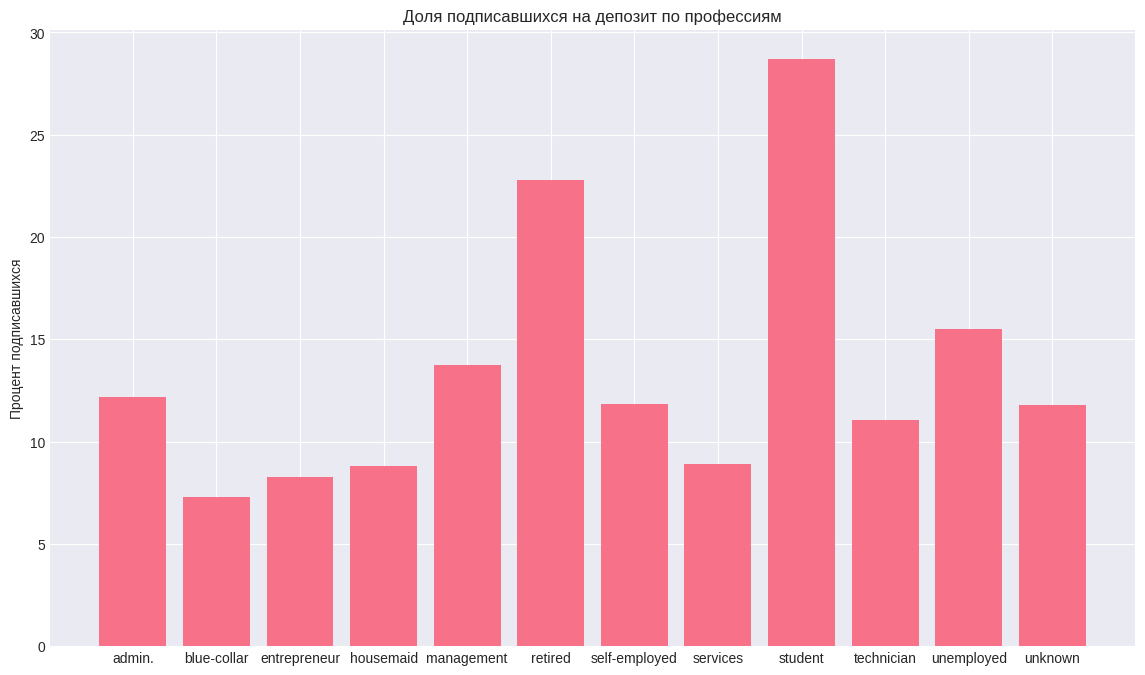

In [ ]:
plt.figure(figsize=(14, 8))
plt.bar(job_stats['job'], job_stats['conv_rate'])
plt.ylabel('Процент подписавшихся')
plt.title('Доля подписавшихся на депозит по профессиям')
plt.show()

Теперь посмотрим как ведут себя группы разделенные по признаку образования

In [ ]:
edu_stats = df.groupby('education').agg(
    n_clients=('y', 'count'),
    conv_rate=('target', 'mean'),
    mean_balance=('balance', 'mean'),
    mean_age=('age', 'mean')
).reset_index()

edu_stats['conv_rate'] = edu_stats['conv_rate'] * 100

edu_stats

,education,n_clients,conv_rate,mean_balance,mean_age
0,primary,6851,8.626478,1250.949934,45.865567
1,secondary,23202,10.559435,1154.880786,39.964270
2,tertiary,13301,15.006390,1758.416435,39.593640
3,unknown,1857,13.570275,1526.754443,44.510501


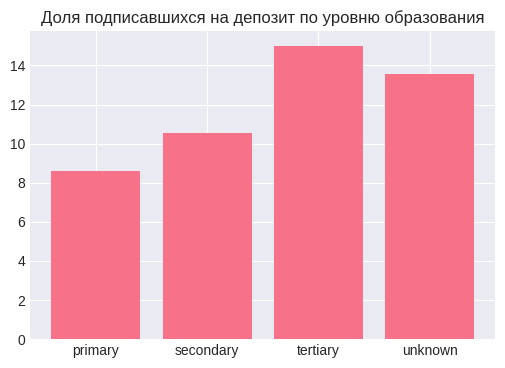

In [ ]:
plt.figure(figsize=(6, 4))
plt.bar(edu_stats['education'], edu_stats['conv_rate'])
plt.title('Доля подписавшихся на депозит по уровню образования')
plt.show()

# Гипотезы

### Гипотеза 1

In [ ]:
bins_age = [0, 30, 40, 50, 60, 100]
labels_age = ['Youth (<30)', 'Adults (31-40)', 'Mid-life (41-50)', 'Pre-senior (51-60)', 'Seniors (60+)']
df['age_group'] = pd.cut(df['age'], bins=bins_age, labels=labels_age)

In [ ]:
age_eda = df.groupby('age_group', observed=False)['target'].mean() * 100

Text(0.5, 0, 'Возрастная группа')

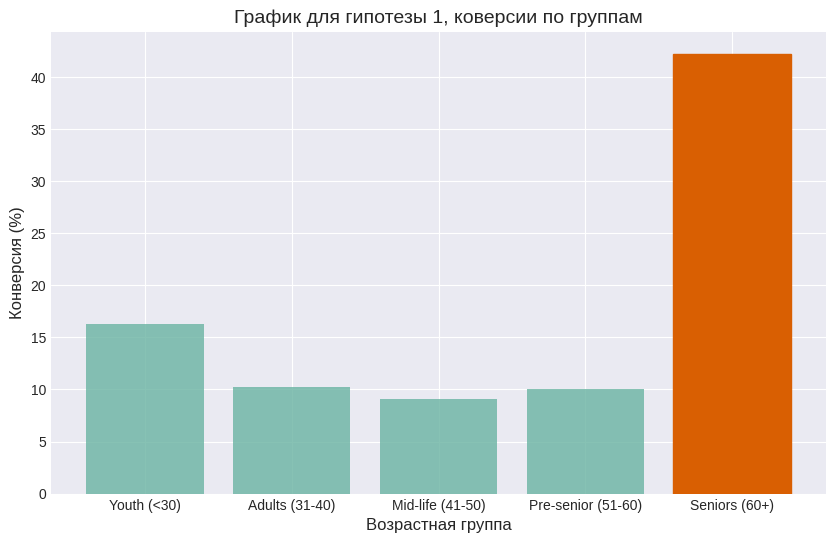

In [ ]:
plt.figure(figsize=(10, 6))
bars = plt.bar(age_eda.index, age_eda.values, color='#69b3a2', alpha=0.8)
bars[-1].set_color('#d95f02')
bars[-1].set_alpha(1.0)

plt.title('График для гипотезы 1, коверсии по группам', fontsize=14)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.xlabel('Возрастная группа', fontsize=12)

In [ ]:
# не работают по возрасту / инвалидности и тд
retired_by_job = df[df['job'] == 'retired']
count_job = len(retired_by_job)
percent_job = (count_job / len(df)) * 100

# пенсионеры
retired_by_age = df[df['age'] >= 60]
count_age = len(retired_by_age)
percent_age = (count_age / len(df)) * 100

# пересечение
real_pensioners = df[(df['job'] == 'retired') & (df['age'] >= 60)]
count_real = len(real_pensioners)


print(len(df))
print(f"{count_age}({percent_age:.2f}%)")
conv_job = (retired_by_job['y'] == 'yes').mean() * 100
conv_age = (retired_by_age['y'] == 'yes').mean() * 100
print(conv_job) # те кто официально не работает по возрасту / инвалидности
print(conv_age) # конвертят пенсионеры
print((df['y'] == 'yes').mean() * 100) # средняя конверсия

45211
1784(3.95%)
22.791519434628977
33.6322869955157
11.698480458295547


**1 гипотеза**

**Из EDA видно, что:**


1.   Пенсионеры (60+) имеют конверсию **40.79% (в 4 раза выше среднего)**
2.   Молодые (18-30) - ниже среднего
3.   Средний возраст 40-50 - baseline

Поэтому,

H₀ (нулевая): Возраст НЕ влияет на вероятность подписки (конверсия одинакова)

H₁ (альтернативная): Существует определённый возрастной диапазон с РЕЗКО ВЫШЕ конверсией

###Стат тесты / эксперименты для гипотезы 1

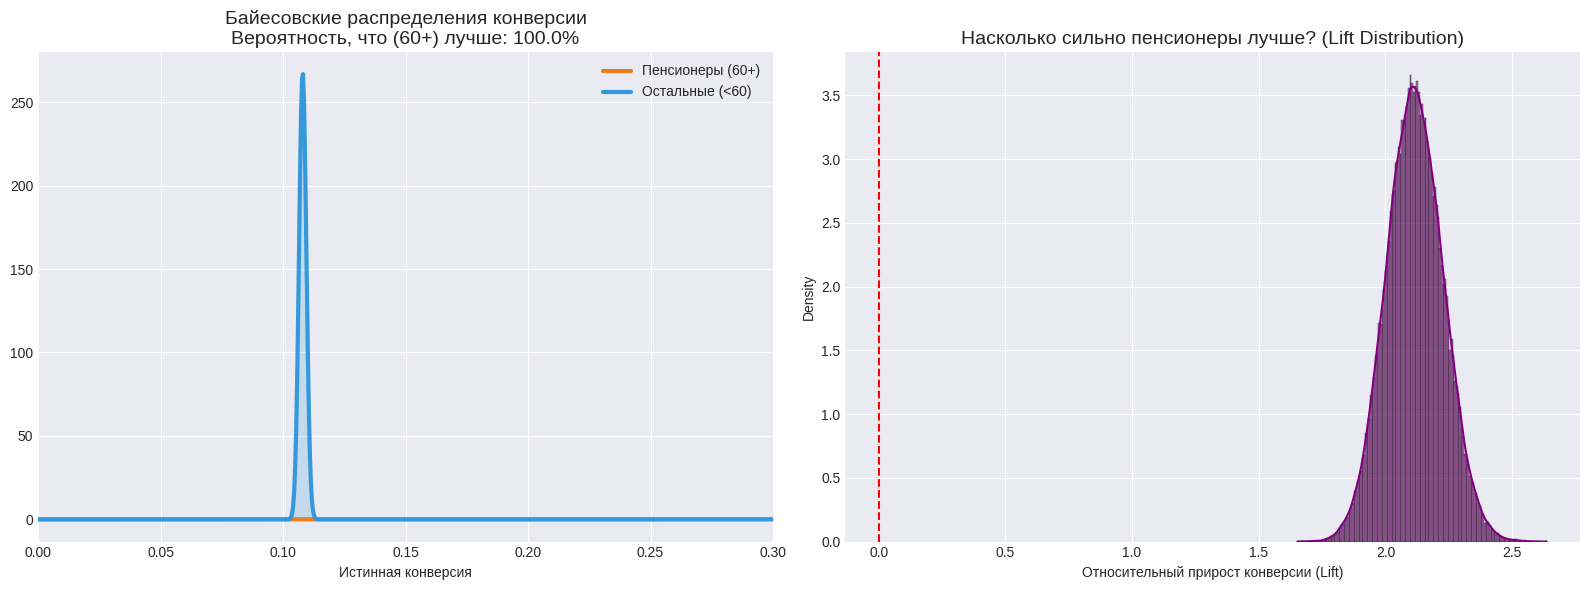

In [ ]:
group_senior = df[df['age'] >= 60]['target']
group_others = df[df['age'] < 60]['target']


def get_beta_params(data):
    successes = data.sum()
    failures = len(data) - successes
    return successes + 1, failures + 1 #+1 для сглаживания лапласа


alpha_sen, beta_sen = get_beta_params(group_senior)
alpha_oth, beta_oth = get_beta_params(group_others)


# Генерируем выборки из распределений (Monte Carlo simulation)
samples_sen = stats.beta.rvs(alpha_sen, beta_sen, size=100000)
samples_oth = stats.beta.rvs(alpha_oth, beta_oth, size=100000)


# Вероятность того, что пенсионеры лучше
prob_better = (samples_sen > samples_oth).mean()


fig, ax = plt.subplots(1, 2, figsize=(16, 6))

# распределеняи
x = np.linspace(0, 0.4, 1000)
y_sen = stats.beta.pdf(x, alpha_sen, beta_sen)
y_oth = stats.beta.pdf(x, alpha_oth, beta_oth)

ax[0].plot(x, y_sen, label='Пенсионеры (60+)', color='#e67e22', lw=3)
ax[0].fill_between(x, 0, y_sen, color='#e67e22', alpha=0.2)
ax[0].plot(x, y_oth, label='Остальные (<60)', color='#3498db', lw=3)
ax[0].fill_between(x, 0, y_oth, color='#3498db', alpha=0.2)
ax[0].set_title(f'Байесовские распределения конверсии\nВероятность, что (60+) лучше: {prob_better*100:.1f}%', fontsize=14)
ax[0].set_xlabel('Истинная конверсия')
ax[0].set_xlim(0, 0.3)
ax[0].legend()

# lift распределение прироста
lift = (samples_sen - samples_oth) / samples_oth
sns.histplot(lift, kde=True, ax=ax[1], color='purple', stat='density')
ax[1].axvline(0, color='red', linestyle='--')
ax[1].set_title('Насколько сильно пенсионеры лучше? (Lift Distribution)', fontsize=14)
ax[1].set_xlabel('Относительный прирост конверсии (Lift)')

plt.tight_layout()
plt.show()

Выбираем тест **хи квадрат**. Почему?

У нас две категориальные переменные
1.   Возрастная группа
2.   Конверсия да / нет (1 / 0)

Хи-квадрат идеально подходит, чтобы проверить, отличается ли распределение подписок в одной группе (пенсионеры) от ожидаемого среднего распределения.

In [ ]:
chi2, p_age, _, _ = stats.chi2_contingency(pd.crosstab(df['age_group'], df['target']))
p_age

np.float64(5.154056324928181e-291)

p_age << 0.05, **гипотеза подтверждена**

###Гипотеза 2

In [ ]:
def categorize_job(job):
    if job in ['student', 'retired', 'unemployed']:
        return 'Non-Active (Student/Retired)'
    elif job in ['blue-collar', 'services', 'housemaid']:
        return 'Blue Collar'
    else:
        return 'White Collar (Admin/Mgmt)'

df['job_category'] = df['job'].apply(categorize_job)

# группируем и считаем конверсию
synergy_eda = df.groupby(['education', 'job_category'], observed=False)['target'].mean().reset_index()
synergy_eda['target'] = synergy_eda['target'] * 100

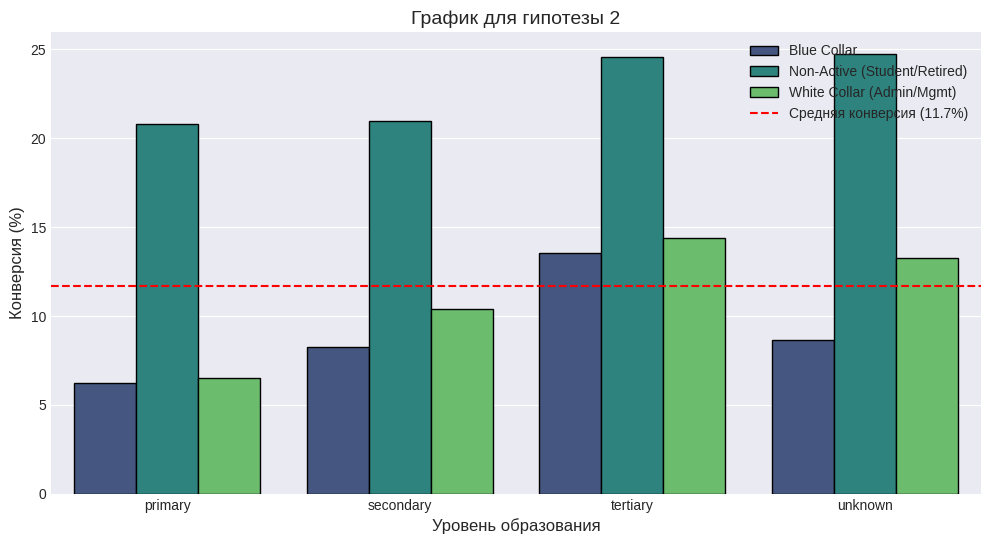

In [ ]:
plt.figure(figsize=(12, 6))

sns.barplot(data=synergy_eda, x='education', y='target', hue='job_category',
            palette='viridis', edgecolor='black')

plt.title('График для гипотезы 2', fontsize=14)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.xlabel('Уровень образования', fontsize=12)
plt.legend(title='Категория занятости')

# Добавляем линию среднего по больнице для сравнения
mean_conv = df['target'].mean() * 100
plt.axhline(y=mean_conv, color='red', linestyle='--', label=f'Средняя конверсия ({mean_conv:.1f}%)')
plt.legend()
plt.show()


**2 гипотеза**

**Из EDA видно, что:**


1.   Tertiary образование: 15% конверсия
2.   Student профессия: 28.68% конверсия

Поэтому,

H₀ (нулевая): Влияние образования и профессии независимо друг от друга

H₁ (альтернативная): Есть синергия между образованием и профессией

###Стат тесты и эксперименты

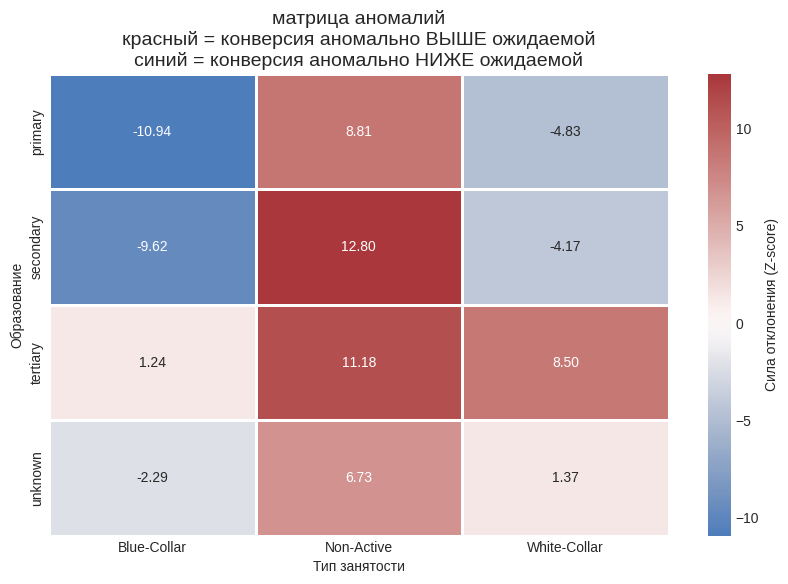

In [ ]:
def categorize_job_simple(job):
    if job in ['student', 'retired', 'unemployed']: return 'Non-Active'
    if job in ['blue-collar', 'services', 'housemaid']: return 'Blue-Collar'
    return 'White-Collar'

df['job_cat'] = df['job'].apply(categorize_job_simple)

observed = pd.crosstab(df['education'], df['job_cat'], values=df['target'], aggfunc='sum').fillna(0)
counts = pd.crosstab(df['education'], df['job_cat'])
global_conversion = df['target'].mean()

# Ожидаемое количество подписок (если бы связи не было) = кол-во людей в ячейке * общая конверсия
expected = counts * global_conversion

# Расчет остатков (Z-score для каждой ячейки)
residuals = (observed - expected) / np.sqrt(expected)

plt.figure(figsize=(10, 6))
sns.heatmap(residuals, annot=True, fmt='.2f', cmap='vlag', center=0,
            linewidths=1, linecolor='white', cbar_kws={'label': 'Сила отклонения (Z-score)'})

plt.title('матрица аномалий\nкрасный = конверсия аномально ВЫШЕ ожидаемой\nсиний = конверсия аномально НИЖЕ ожидаемой', fontsize=14)
plt.ylabel('Образование')
plt.xlabel('Тип занятости')
plt.show()

In [ ]:
model_int = smf.logit("target ~ education * job", data=df).fit(disp=0)
p_synergy = model_int.pvalues[model_int.pvalues.index.str.contains(':')].min()
p_synergy

0.00031494878059288927

p_synergy << 0.05, **гипотеза подтверждена**

###3 гипотеза

In [ ]:
labels = ['very low', 'low', 'medium', 'high', 'very high']
df['balance_group'] = pd.qcut(df['balance'], q=5, labels=labels)

balance_eda = (df.groupby('balance_group', observed=False)['target'].mean() * 100)
balance_eda

,target
balance_group,
very low,6.959019
low,10.000000
medium,11.711212
high,13.463879
very high,16.368060


Text(0.5, 0, 'Уровень баланса')

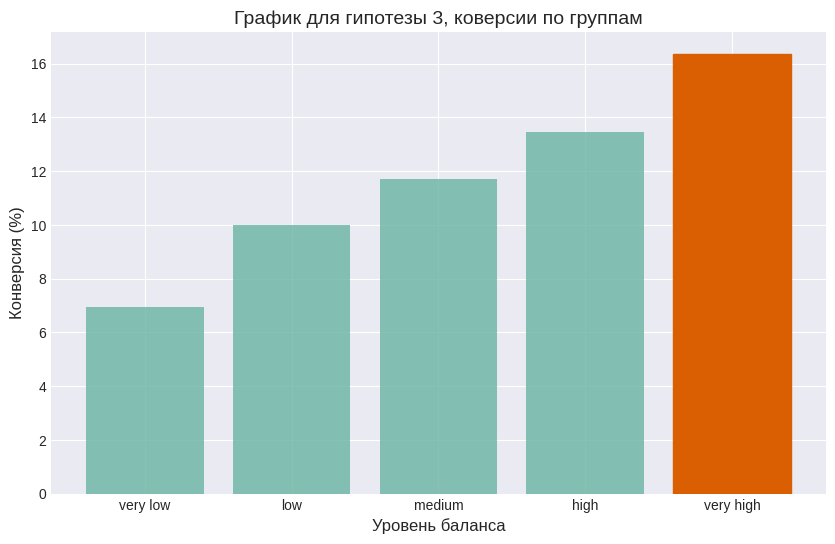

In [ ]:
plt.figure(figsize=(10, 6))
bars = plt.bar(balance_eda.index, balance_eda.values, color='#69b3a2', alpha=0.8)
bars[-1].set_color('#d95f02')
bars[-1].set_alpha(1.0)

plt.title('График для гипотезы 3, коверсии по группам', fontsize=14)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.xlabel('Уровень баланса', fontsize=12)

**Гипотеза 3**

H₀ (нулевая): Вероятность открытия депозита не зависит от уровня баланса

H₁ (альтернативная): Депозит чаще открывают люди с более высоким балансом

###Стат тесты для 3 гипотезы

###4 гипотеза

In [ ]:
df['campaign'].unique()

array([ 1,  2,  3,  5,  4,  6,  7,  8,  9, 10, 11, 12, 13, 19, 14, 24, 16,
       32, 18, 22, 15, 17, 25, 21, 43, 51, 63, 41, 26, 28, 55, 50, 38, 23,
       20, 29, 31, 37, 30, 46, 27, 58, 33, 35, 34, 36, 39, 44])

In [ ]:
bins = [0, 10, 20, 30, 44]
labels = ['1–10', '11–20', '21–30', '31–44']

df['campaign_group'] = pd.cut(df['campaign'], bins=bins, labels=labels, right=True, include_lowest=True)

campaign_eda = (df.groupby('campaign_group', observed=False)['target'].mean() * 100)

campaign_eda

,target
campaign_group,
1–10,11.909576
11–20,4.516807
21–30,1.621622
31–44,1.923077


Text(0.5, 0, 'Количество контактов с клиентом')

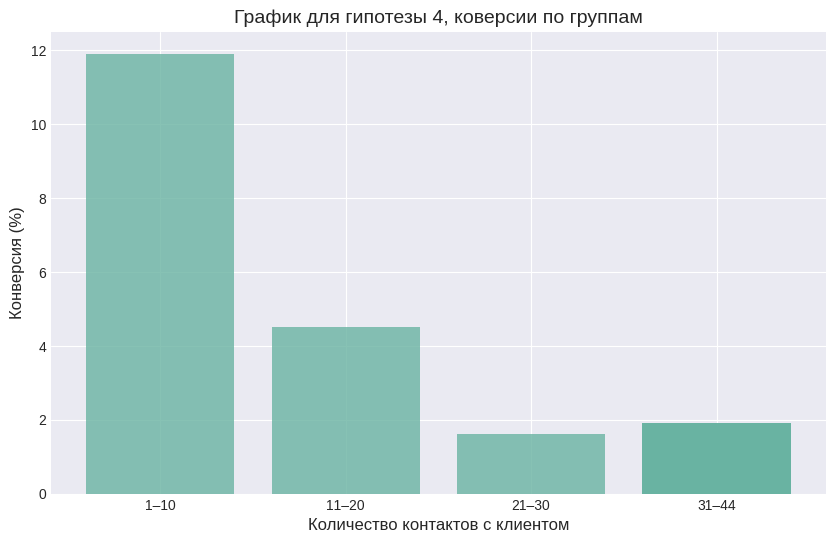

In [ ]:
plt.figure(figsize=(10, 6))
bars = plt.bar(campaign_eda.index, campaign_eda.values, color='#69b3a2', alpha=0.8)
#bars[-1].set_color('#d95f02')
bars[-1].set_alpha(1.0)

plt.title('График для гипотезы 4, коверсии по группам', fontsize=14)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.xlabel('Количество контактов с клиентом', fontsize=12)

**Гипотеза 4**

H₀ (нулевая): Количество контактов в текущей кампании не влияет на вероятность оформления депозита

H₁ (альтернативная): При увеличении контактов вероятность оформления депозита снижается

###Стат тесты для 4 гипотезы

###Гипотеза 5

In [ ]:
bins = [0, 5, 10, 15, 20, 25, 31]
labels = ['1–5', '6-10', '11-15', '16–20', '21-25', '26–31']

df['day_group'] = pd.cut(df['day'], bins=bins, labels=labels, right=True, include_lowest=True)

day_eda = (df.groupby('day_group', observed=False)['target'].mean() * 100)

day_eda

,target
day_group,
1–5,14.795834
6-10,10.930172
11-15,13.555610
16–20,8.947006
21-25,13.108396
26–31,10.768262


Text(0.5, 0, 'Число месяа')

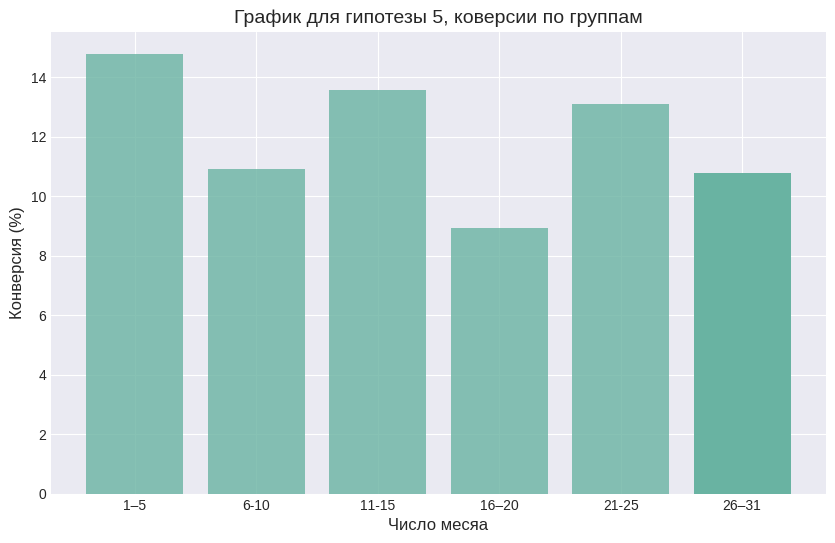

In [ ]:
plt.figure(figsize=(10, 6))
bars = plt.bar(day_eda.index, day_eda.values, color='#69b3a2', alpha=0.8)
#bars[-1].set_color('#d95f02')
bars[-1].set_alpha(1.0)

plt.title('График для гипотезы 5, коверсии по группам', fontsize=14)
plt.ylabel('Конверсия (%)', fontsize=12)
plt.xlabel('Число месяа', fontsize=12)

**Гипотеза 5**

H₀ (нулевая): День месяца не влияет на вероятность открытия депозита

H₁ (альтернативная): В начале месяца вероятность открытия депозита выше

###Стат тесты для 5 гипотезы

###6 гипотеза

In [ ]:
df['age_segment'] = 'young'

df.loc[df['age_group'].isin([
    'Mid-life (41-50)',
    'Pre-senior (51-60)',
    'Seniors (60+)'
]), 'age_segment'] = 'old'

print(df['age_group'].value_counts())
print("\nage_segment:")
print(df['age_segment'].value_counts())


age_group
Adults (31-40)        17687
Mid-life (41-50)      11239
Pre-senior (51-60)     8067
Youth (<30)            7030
Seniors (60+)          1188
Name: count, dtype: int64

age_segment:
age_segment
young    24717
old      20494
Name: count, dtype: int64


In [ ]:
conv_age_camp = (
    df.groupby(['age_segment', 'campaign_group'])['target']
      .mean() * 100
).reset_index()

print("\nКонверсия по age_segment и campaign_group (%):")
print(conv_age_camp)


Конверсия по age_segment и campaign_group (%):
  age_segment campaign_group     target
0         old           1–10  11.601684
1         old          11–20   3.401361
2         old          21–30   1.282051
3         old          31–44   5.000000
4       young           1–10  12.164914
5       young          11–20   5.479452
6       young          21–30   1.869159
7       young          31–44   0.000000


/tmp/ipython-input-251359959.py:2: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  df.groupby(['age_segment', 'campaign_group'])['target']


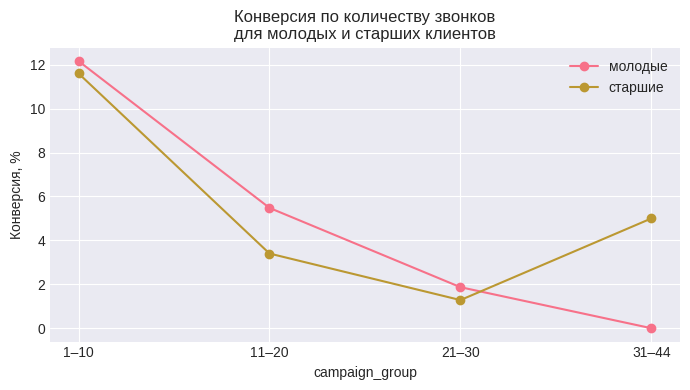

In [ ]:
young = conv_age_camp[conv_age_camp['age_segment'] == 'young']
old   = conv_age_camp[conv_age_camp['age_segment'] == 'old']

plt.figure(figsize=(7, 4))

plt.plot(young['campaign_group'], young['target'], marker='o', label='молодые')
plt.plot(old['campaign_group'],   old['target'],   marker='o', label='старшие')

plt.xlabel('campaign_group')
plt.ylabel('Конверсия, %')
plt.title('Конверсия по количеству звонков\nдля молодых и старших клиентов')
plt.legend()
plt.grid(True)
plt.show()

H₀: влияние количества звонков на конверсию одинаково для молодых и старших клиентов.

H₁: у молодых клиентов конверсия сильнее падает при росте количества звонков, чем у старших.

 Z-тест, бутстрап

###Стат тесты для 6 гипотезы

###7 гипотеза

H0: Наличие успешного результата предыдущей кампании (poutcome = success) не связано с текущей подпиской.

H1: Если предыдущая кампания была успешной, клиент сейчас подписывает депозит чаще.


In [40]:
df_clean = df[df['poutcome'] != 'unknown']

In [41]:
df_clean['poutcome_bin'] = df_clean['poutcome'].apply(
    lambda x: 'success' if x == 'success' else 'other'
)

# Строим таблицу сопряжённости 2×2
table = pd.crosstab(df_clean['poutcome_bin'], df_clean['y'])
print(table)

y               no  yes
poutcome_bin           
other         5816  925
success        533  978


In [47]:
from scipy.stats import chi2_contingency

chi2, p, dof, expected = chi2_contingency(table)

print(f'chi2 = {chi2:.4f}')
print(f'p-value = {p:.500f}')
print('Ожидаемые частоты:')
print(expected)

chi2 = 1806.8044
p-value = 0.00000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000000
Ожидаемые частоты:
[[5186.45285991 1554.54714009]
 [1162.54714009  348.45285991]]


In [43]:
import numpy as np

# Пусть порядок индексов и столбцов такой:
# index: ['other', 'success'], columns: ['no', 'yes']
a = table.loc['success', 'yes']
b = table.loc['success', 'no']
c = table.loc['other',   'yes']
d = table.loc['other',   'no']

# Отношение шансов
odds_ratio = (a / b) / (c / d)
print(f'Odds ratio = {odds_ratio:.4f}')

Odds ratio = 11.5370


  poutcome_bin  conversion_rate
0        other         0.137220
1      success         0.647253


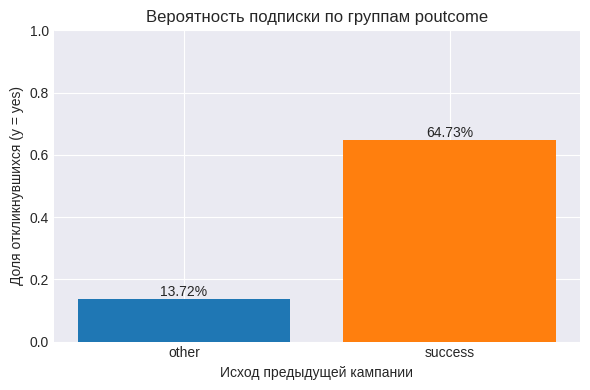

In [44]:
# Бинаризуем poutcome
df_clean['poutcome_bin'] = df_clean['poutcome'].apply(
    lambda x: 'success' if x == 'success' else 'other'
)

# Считаем долю откликов в каждой группе
conv_rates = (
    df_clean.groupby('poutcome_bin')['y']
      .apply(lambda s: (s == 'yes').mean())
      .reset_index(name='conversion_rate')
)

print(conv_rates)

# Столбчатая диаграмма
plt.figure(figsize=(6, 4))
plt.bar(conv_rates['poutcome_bin'], conv_rates['conversion_rate'], color=['tab:blue', 'tab:orange'])
plt.ylabel('Доля откликнувшихся (y = yes)')
plt.xlabel('Исход предыдущей кампании')
plt.title('Вероятность подписки по группам poutcome')
plt.ylim(0, 1)
for x, y in zip(conv_rates['poutcome_bin'], conv_rates['conversion_rate']):
    plt.text(x, y + 0.01, f'{y:.2%}', ha='center')
plt.tight_layout()
plt.show()


In [45]:
df_clean['poutcome_bin'].value_counts()

,count
poutcome_bin,
other,6741
success,1511


ВЫВОДЫ:

Гипотеза проверена с помощью критерия хи-квадрат, подтверждена статистическая значимость связи.

Рассчитано отношение шансов, показавшее сильное влияние прошлого успеха на текущую конверсию.

p-value ≈ 0.0000000000 — крайне малая величина, что указывает на высокую статистическую значимость связи между переменными.

Гипотеза Н0 отвергается. Гипотеза Н1 (о наличии связи) подтверждается.

Сила связи между переменными:

Отношение шансов (Odds Ratio) = 11.5370 — это означает, что шансы на отклик у клиентов с успешной предыдущей кампанией в 11.5 раз выше, чем у остальных.

Это свидетельствует о сильном влиянии прошлого успеха на текущее поведение клиента.

Клиенты с успешным опытом взаимодействия являются одной из ключевой целевой аудиторией для новых предложений.

Следует активнее вовлекать эту группу клиентов в новые кампании, так как их лояльность и отзывчивость значительно выше.

Для клиентов из группы "other" можно рассмотреть дополнительные стимулы или персонализированные предложения, чтобы повысить их вовлечённость.